In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('FRED_DGS10.csv', skiprows=10)
df.columns = ['Date', 'Yield']

In [7]:
df['Yield'] = pd.to_numeric(df['Yield'], errors='coerce')

In [8]:
df['Yield'] = df['Yield'].ffill()
df = df.dropna().reset_index(drop=True)

In [9]:
df['Yield_Dec'] = df['Yield'] / 100.0

In [10]:
print(f"Data Cleaned. Total observation rows processed: {len(df)}")

Data Cleaned. Total observation rows processed: 2620


In [11]:
# Delta t represents 1 trading day out of 252 business days in a year
dt = 1 / 252

# Set up current and one-day lagged arrays to execute a linear regression
r_current = df['Yield_Dec'].values[1:]
r_lagged = df['Yield_Dec'].values[:-1]

# Discretized Vasicek via Ordinary Least Squares (OLS): delta_r / dt = a + b * r_lagged
Y = (r_current - r_lagged) / dt
X = r_lagged

# Fit a line (degree 1 polynomial)
slope, intercept = np.polyfit(X, Y, 1)

# Extract structural parameters
k = -slope            # Speed of mean reversion
theta = intercept / k # Long-term mean level

# Calculate daily volatility from regression residuals
residuals = Y - (slope * X + intercept)
sigma = np.std(residuals) * np.sqrt(dt)

print("==== HISTORICAL CALIBRATION METRICS ====")
print(f"Speed of Mean Reversion (k):  {k:.4f}")
print(f"Long-Term Mean Yield (theta):  {theta * 100:.2f}%")
print(f"Annual Volatility (sigma):     {sigma * 100:.2f}%")


==== HISTORICAL CALIBRATION METRICS ====
Speed of Mean Reversion (k):  0.0904
Long-Term Mean Yield (theta):  6.70%
Annual Volatility (sigma):     0.83%


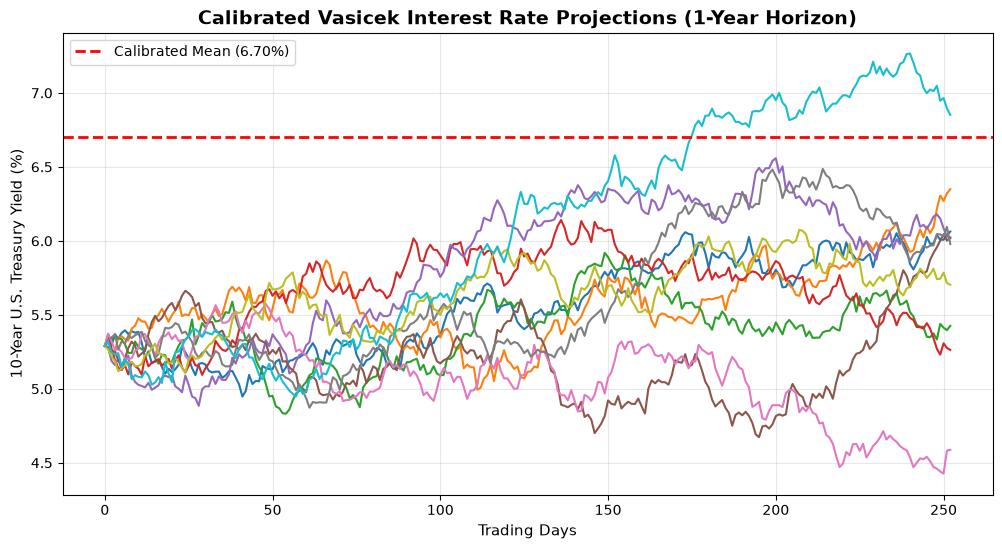

In [12]:
def run_vasicek_simulation(r0, k, theta, sigma, T, steps, paths):
    dt_sim = T / steps
    rates = np.zeros((steps + 1, paths))
    rates[0, :] = r0
    
    for t in range(1, steps + 1):
        # Generate random Gaussian shocks (Brownian Motion)
        dW = np.random.normal(0, np.sqrt(dt_sim), paths)
        drift = k * (theta - rates[t-1, :]) * dt_sim
        shock = sigma * dW
        rates[t, :] = rates[t-1, :] + drift + shock
    return rates

# Simulation Configs
r0 = df['Yield_Dec'].iloc[-1] # Pull the last actual observed historical yield
T = 1.0                       # 1-year predictive horizon
steps = 252                   # Daily intervals
paths = 10                    # Generate 10 random potential tracks

np.random.seed(42) # Locked seed for consistent generation profiles
sim_paths = run_vasicek_simulation(r0, k, theta, sigma, T, steps, paths)

# Plotting the engine profiles
plt.figure(figsize=(12, 6))
plt.plot(sim_paths * 100, lw=1.5)
plt.axhline(theta * 100, color='red', linestyle='--', lw=2, label=f'Calibrated Mean ({theta*100:.2f}%)')
plt.title('Calibrated Vasicek Interest Rate Projections (1-Year Horizon)', fontsize=14, fontweight='bold')
plt.xlabel('Trading Days', fontsize=11)
plt.ylabel('10-Year U.S. Treasury Yield (%)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
